# Phase 8 & 9: Latent Sentiment Mapping & Sentiment Derivation
### Project: Multidimensional Emotion-to-Sentiment Derivation and Mapping

Welcome to **Notebook 8: Latent Sentiment Mapping & Sentiment Derivation Experiments**.

This notebook implements and validates **Stage 8: Latent Sentiment Mapping** and **Stage 9: Sentiment Derivation and Mapping** in accordance with `AGENTS.md`:

1. **Environment Setup & Configuration**: Path resolution across Google Colab GPU and local environments, loading `configs/model.yaml`.
2. **Ground Truth Valence-to-Sentiment Grounding**: Documenting the methodology that maps continuous EmoReact valence ratings ($1.0$ to $7.0$) to 3-class sentiment (`Negative`, `Neutral`, `Positive`) with a neutral deadband margin ($0.25$).
3. **Latent Sentiment Mapping (`LatentSentimentMapper`)**: Synthesizing the 4 streams:
   - Emotion Dynamics (current probabilities, confidence, velocity $\Delta E$, persistence)
   - Uncertainty-Gated Context Representation
   - Composite Transition Embeddings
   - Continuous Affective Valence Representation
4. **Temporal Attention Pooling**: Differentiable attention mechanism determining the relative saliency of each temporal step in deriving the final sentiment.
5. **Sentiment Derivation Head (`SentimentHead`)**: Deriving 3-class categorical sentiment probabilities and continuous sentiment polarity score ($-1.0$ to $1.0$).
6. **Sentiment-Level Confidence Estimation**: Evaluating margin, max probability, and entropy confidence metrics.
7. **Complete End-to-End 9-Stage Pipeline**: Connecting Modality Alignment $\to$ Fusion $\to$ BiLSTM $\to$ Emotion $\to$ Transitions $\to$ Uncertainty Gate $\to$ Latent Mapper $\to$ Sentiment Head.
8. **Readiness for Stage 10 Explainable AI (XAI)**: Preserving latent representations and attention weights for feature attribution and modality explanations.

---
## 1. Setup, Environment & Path Resolution

We configure the environment, establish paths, and set reproducible seeds.

In [1]:
import os
import sys
import json
from pathlib import Path
import yaml
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Detect workspace root and add src/ to Python path
def find_project_root() -> Path:
    candidate = Path.cwd().resolve()
    for _ in range(4):
        if (candidate / "configs").exists() and (candidate / "src").exists():
            return candidate
        candidate = candidate.parent
    return Path.cwd().resolve()

PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project Root           : {PROJECT_ROOT}")
print(f"Added to sys.path      : {SRC_DIR}")
print(f"Execution Device       : {DEVICE}")

Project Root           : C:\Niladri\empty\coding\projects\Multimodal-Sentiment-Derivation
Added to sys.path      : C:\Niladri\empty\coding\projects\Multimodal-Sentiment-Derivation\src
Execution Device       : cpu


---
## 2. Ground Truth Valence-to-Sentiment Derivation

> **`AGENTS.md` Section 8 Constraint**: *"Emotional labels and sentiment labels are not necessarily interchangeable. If the dataset does not directly provide the required sentiment ground truth, explicitly document the derivation methodology and its limitations. Do not silently manufacture ground-truth sentiment labels."*

In EmoReact, human annotators rated continuous valence on a Likert scale from $1.0$ (strongly negative) to $7.0$ (strongly positive) with $4.0$ as neutral.

Our documented mapping with neutral margin $\delta = 0.25$:
- **Negative (0)**: $\text{valence} < 3.75$
- **Neutral (1)**: $3.75 \le \text{valence} \le 4.25$
- **Positive (2)**: $\text{valence} > 4.25$
- **Normalized Score**: $s = \frac{\text{valence} - 4.0}{3.0} \in [-1.0, 1.0]$

Valence-to-Sentiment Mapping Demonstration:
Valence    Class Index    Sentiment    Normalized Score  
------------------------------------------------------
1.20       0              Negative     -0.9333           
2.50       0              Negative     -0.5000           
3.70       0              Negative     -0.1000           
3.90       1              Neutral      -0.0333           
4.00       1              Neutral      +0.0000           
4.20       1              Neutral      +0.0667           
4.80       2              Positive     +0.2667           
6.20       2              Positive     +0.7333           


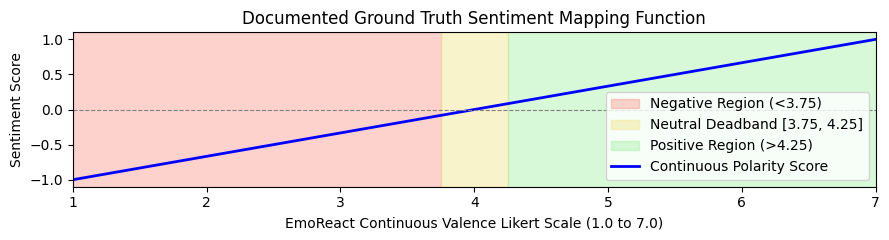

In [2]:
from sentiment_derivation.sentiment import (
    DEFAULT_SENTIMENT_NAMES,
    NUM_SENTIMENT_CLASSES,
    valence_to_sentiment_label,
)

# Evaluate on test valence points
test_valences = [1.2, 2.5, 3.7, 3.9, 4.0, 4.2, 4.8, 6.2]
classes, labels, scores = valence_to_sentiment_label(test_valences, neutral_margin=0.25)

print("Valence-to-Sentiment Mapping Demonstration:")
print(f"{'Valence':<10} {'Class Index':<14} {'Sentiment':<12} {'Normalized Score':<18}")
print("-" * 54)
for v, c, l, s in zip(test_valences, classes, labels, scores):
    print(f"{v:<10.2f} {c:<14} {l:<12} {s:<+18.4f}")

# Visualize the 3 sentiment regions
v_sweep = np.linspace(1.0, 7.0, 300)
_, _, s_sweep = valence_to_sentiment_label(v_sweep, neutral_margin=0.25)

plt.figure(figsize=(9, 2.5))
plt.axvspan(1.0, 3.75, color='salmon', alpha=0.35, label='Negative Region (<3.75)')
plt.axvspan(3.75, 4.25, color='khaki', alpha=0.45, label='Neutral Deadband [3.75, 4.25]')
plt.axvspan(4.25, 7.0, color='lightgreen', alpha=0.35, label='Positive Region (>4.25)')
plt.plot(v_sweep, s_sweep, 'b-', linewidth=2, label='Continuous Polarity Score')
plt.axhline(0.0, color='gray', linestyle='--', linewidth=0.8)
plt.xlim(1.0, 7.0)
plt.ylim(-1.1, 1.1)
plt.xlabel("EmoReact Continuous Valence Likert Scale (1.0 to 7.0)")
plt.ylabel("Sentiment Score")
plt.title("Documented Ground Truth Sentiment Mapping Function")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
## 3. Module Initialization via Configuration

We instantiate `LatentSentimentMapper`, `SentimentHead`, and `SentimentDerivationPipeline` directly from `configs/model.yaml`.

In [3]:
from sentiment_derivation.sentiment import (
    LatentSentimentMapper,
    LatentSentimentOutput,
    SentimentHead,
    SentimentOutput,
    SentimentDerivationPipeline,
)

# Load model configuration
with open(PROJECT_ROOT / "configs" / "model.yaml", "r", encoding="utf-8") as f:
    model_cfg = yaml.safe_load(f)

latent_mapper = LatentSentimentMapper.from_config(model_cfg).to(DEVICE)
sentiment_head = SentimentHead.from_config(model_cfg).to(DEVICE)
sentiment_pipeline = SentimentDerivationPipeline(latent_mapper, sentiment_head).to(DEVICE)

total_mapper_params = sum(p.numel() for p in latent_mapper.parameters())
total_head_params = sum(p.numel() for p in sentiment_head.parameters())
total_params = total_mapper_params + total_head_params

print("[Sentiment Module Architecture Summary]")
print(f"- LatentMapper Input Gated Feature Dim : {latent_mapper.feature_dim}")
print(f"- LatentMapper Latent Dimension        : {latent_mapper.latent_dim}")
print(f"- LatentMapper Temporal Pooling Mode   : {latent_mapper.temporal_pooling}")
print(f"- SentimentHead Output Classes         : {sentiment_head.num_classes} ({', '.join(sentiment_head.sentiment_labels)})")
print(f"- SentimentHead Confidence Method      : {sentiment_head.confidence_method}")
print(f"- Total Stage 8 & 9 Parameters         : {total_params:,} (Mapper: {total_mapper_params:,}, Head: {total_head_params:,})")

[Sentiment Module Architecture Summary]
- LatentMapper Input Gated Feature Dim : 128
- LatentMapper Latent Dimension        : 128
- LatentMapper Temporal Pooling Mode   : attention
- SentimentHead Output Classes         : 3 (Negative, Neutral, Positive)
- SentimentHead Confidence Method      : margin
- Total Stage 8 & 9 Parameters         : 83,940 (Mapper: 75,296, Head: 8,644)


---
## 4. Experiment 1: Disentangled Stream Synthesis in `LatentSentimentMapper`

`LatentSentimentMapper` synthesizes 4 distinct informational streams into a unified latent affective vector:
1. **Emotion Dynamics Stream**: Current probabilities ($8$), confidence ($8$), velocity $\Delta E$ ($8$), and persistence ($8$) ($32$ dims total).
2. **Gated Context Stream**: Uncertainty-modulated representations ($128$ dims).
3. **Transition Stream**: Emotion evolution embeddings from Stage 6 ($128$ dims).
4. **Affective Stream**: Continuous valence representation ($64$ dims).

Latent Sequence Shape       : (3, 16, 128) [B, T=16, D_latent=128]
Pooled Latent Representation: (3, 128) [B, D_latent=128]
Temporal Attention Shape    : (3, 16, 1) [B, T=16, 1]


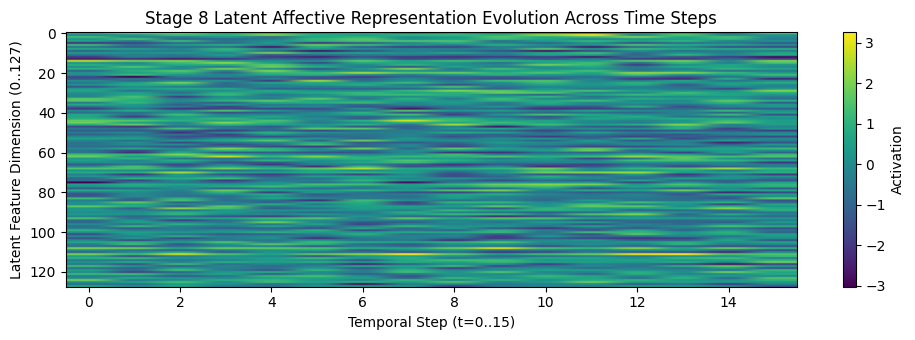

In [4]:
batch_size = 3
steps = 16

# Simulate inputs matching Stage 4-7 outputs
gated_features = torch.randn(batch_size, steps, 128, device=DEVICE)
emotion_probs = torch.sigmoid(torch.randn(batch_size, steps, 8, device=DEVICE))
emotion_conf = torch.rand(batch_size, steps, 8, device=DEVICE)
delta_emotion = torch.clamp(torch.randn(batch_size, steps, 8, device=DEVICE) * 0.3, -1.0, 1.0)
persistence = torch.rand(batch_size, steps, 8, device=DEVICE)
transition_emb = torch.randn(batch_size, steps, 128, device=DEVICE)
affective_state = torch.randn(batch_size, steps, 64, device=DEVICE)

with torch.no_grad():
    latent_out = latent_mapper(
        gated_features=gated_features,
        emotion_probabilities=emotion_probs,
        emotion_confidence=emotion_conf,
        delta_emotion=delta_emotion,
        persistence=persistence,
        transition_embedding=transition_emb,
        affective_state=affective_state,
    )

print(f"Latent Sequence Shape       : {tuple(latent_out.latent_sequence.shape)} [B, T=16, D_latent=128]")
print(f"Pooled Latent Representation: {tuple(latent_out.latent_representation.shape)} [B, D_latent=128]")
print(f"Temporal Attention Shape    : {tuple(latent_out.temporal_attention_weights.shape)} [B, T=16, 1]")

# Visualize the evolving latent representation across time steps
plt.figure(figsize=(10, 3.5))
plt.imshow(latent_out.latent_sequence[0].cpu().numpy().T, aspect='auto', cmap='viridis')
plt.colorbar(label="Activation")
plt.xlabel("Temporal Step (t=0..15)")
plt.ylabel("Latent Feature Dimension (0..127)")
plt.title("Stage 8 Latent Affective Representation Evolution Across Time Steps")
plt.tight_layout()
plt.show()

---
## 5. Experiment 2: Temporal Attention Saliency Across Time Steps

The attention mechanism $\alpha_t = \text{Softmax}(\mathbf{w}^T \tanh(\mathbf{W} \mathbf{z}_t))$ determines the contribution of each temporal step in deriving the clip-level sentiment vector:
$$\mathbf{z}_{\text{pooled}} = \sum_{t=1}^T \alpha_t \mathbf{z}_t$$
This temporal attention is essential for **Stage 10 Explainable AI (XAI)** to identify which emotional transition moment drove the overall sentiment.

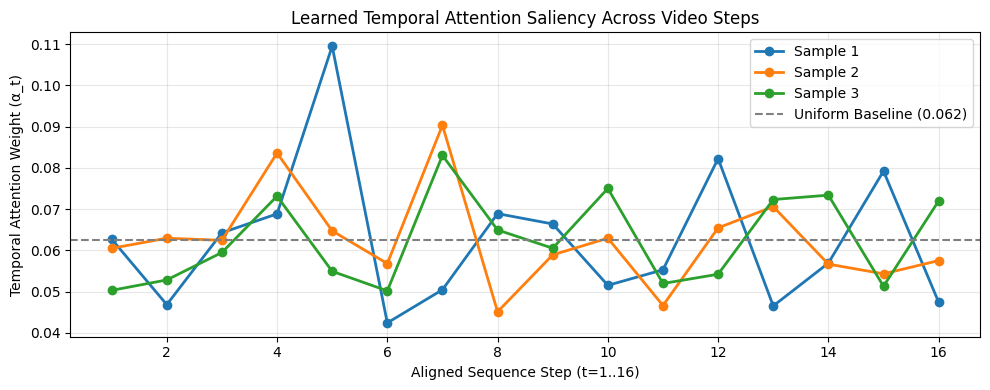

In [5]:
attn_weights = latent_out.temporal_attention_weights.cpu().numpy()  # [B=3, T=16, 1]
time_axis = np.arange(1, steps + 1)

plt.figure(figsize=(10, 4))
for b in range(batch_size):
    plt.plot(time_axis, attn_weights[b].flatten(), marker='o', linewidth=2, label=f'Sample {b+1}')
plt.axhline(1.0 / steps, color='gray', linestyle='--', label=f'Uniform Baseline ({1.0/steps:.3f})')
plt.xlabel("Aligned Sequence Step (t=1..16)")
plt.ylabel("Temporal Attention Weight (\u03b1_t)")
plt.title("Learned Temporal Attention Saliency Across Video Steps")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

---
## 6. Experiment 3: Sentiment Classification & Continuous Polarity Derivation

`SentimentHead` derives both:
1. **3-Class Softmax Distribution**: Probabilities over $\text{Negative}$, $\text{Neutral}$, $\text{Positive}$.
2. **Continuous Polarity Score**: Real-valued score $s \in [-1.0, 1.0]$.
3. **Sentiment Confidence**: Normalized prediction certainty $c \in [0.0, 1.0]$.

Stage 9 Sentiment Derivation Results:
Sample   Predicted    Neg Prob   Neu Prob   Pos Prob   Polarity   Confidence
--------------------------------------------------------------------------
1        Negative     0.389      0.279      0.332      -0.290     0.057     
2        Positive     0.194      0.351      0.455      -0.390     0.104     
3        Positive     0.321      0.326      0.352      +0.034     0.026     


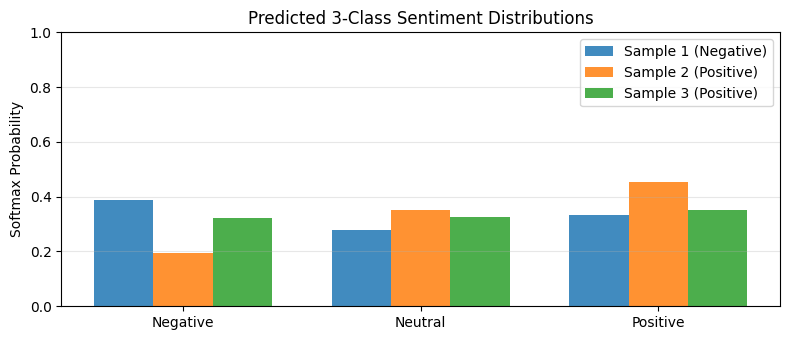

In [6]:
with torch.no_grad():
    sentiment_out = sentiment_head(latent_out.latent_representation)

probs = sentiment_out.sentiment_probabilities.cpu().numpy()  # [3, 3]
scores = sentiment_out.sentiment_score.cpu().numpy().flatten()  # [3]
confs = sentiment_out.sentiment_confidence.cpu().numpy()  # [3]
preds = sentiment_out.sentiment

print("Stage 9 Sentiment Derivation Results:")
print(f"{'Sample':<8} {'Predicted':<12} {'Neg Prob':<10} {'Neu Prob':<10} {'Pos Prob':<10} {'Polarity':<10} {'Confidence':<10}")
print("-" * 74)
for b in range(batch_size):
    print(f"{b+1:<8} {preds[b]:<12} {probs[b,0]:<10.3f} {probs[b,1]:<10.3f} {probs[b,2]:<10.3f} {scores[b]:<+10.3f} {confs[b]:<10.3f}")

# Bar chart of 3-class probabilities
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(NUM_SENTIMENT_CLASSES)
width = 0.25

for b in range(batch_size):
    ax.bar(x + (b - 1) * width, probs[b], width, label=f'Sample {b+1} ({preds[b]})', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(DEFAULT_SENTIMENT_NAMES)
ax.set_ylabel("Softmax Probability")
ax.set_ylim(0.0, 1.0)
ax.set_title("Predicted 3-Class Sentiment Distributions")
ax.grid(True, alpha=0.3, axis='y')
ax.legend()
plt.tight_layout()
plt.show()

---
## 7. Experiment 4: Sentiment Confidence Estimation Analysis

We compare 3 confidence estimation strategies for sentiment:
- **Margin Confidence**: $c = p_{(1)} - p_{(2)}$ (separation between top two classes).
- **Max Probability**: $c = \max_c p_c$.
- **Normalized Negative Entropy**: $c = 1 - \frac{H(\mathbf{p})}{\ln 3}$.

In [7]:
# Synthetic probability distributions representing varied certainty states
synth_probs = torch.tensor([
    [0.90, 0.05, 0.05],  # Decisive prediction
    [0.60, 0.30, 0.10],  # Moderate certainty
    [0.45, 0.40, 0.15],  # Highly ambiguous decision boundary
    [0.34, 0.33, 0.33],  # Maximal uncertainty (uniform)
])

head_margin = SentimentHead(confidence_method="margin")
head_max = SentimentHead(confidence_method="max_prob")
head_entropy = SentimentHead(confidence_method="entropy")

conf_m = head_margin._estimate_sentiment_confidence(synth_probs).numpy()
conf_p = head_max._estimate_sentiment_confidence(synth_probs).numpy()
conf_e = head_entropy._estimate_sentiment_confidence(synth_probs).numpy()

print(f"{'Case Description':<32} {'Top-1':<8} {'Margin':<10} {'MaxProb':<10} {'Entropy':<10}")
print("-" * 70)
cases = ["Decisive (90-5-5)", "Moderate (60-30-10)", "Ambiguous (45-40-15)", "Uniform (34-33-33)"]
for c_name, p, m, mp, e in zip(cases, synth_probs, conf_m, conf_p, conf_e):
    print(f"{c_name:<32} {p.max():<8.2f} {m:<10.3f} {mp:<10.3f} {e:<10.3f}")

Case Description                 Top-1    Margin     MaxProb    Entropy   
----------------------------------------------------------------------
Decisive (90-5-5)                0.90     0.850      0.900      0.641     
Moderate (60-30-10)              0.60     0.300      0.600      0.183     
Ambiguous (45-40-15)             0.45     0.050      0.450      0.080     
Uniform (34-33-33)               0.34     0.010      0.340      0.000     


---
## 8. Experiment 5: Complete 9-Stage End-to-End Pipeline Demonstration

We now assemble the **complete end-to-end derivation pipeline** across all 9 canonical stages:

$$\text{Multimodal Input} \to \text{Aligner} \to \text{Fusion} \to \text{BiLSTM} \to \text{Emotion/Affect} \to \text{Transitions} \to \text{Gate} \to \text{Latent Mapper} \to \text{Sentiment Head}$$

This validates the unified **`AGENTS.md` Section 6 Contract**.

In [8]:
from sentiment_derivation.fusion.alignment import ModalityAligner
from sentiment_derivation.fusion.multimodal_fusion import MultimodalFusion
from sentiment_derivation.temporal import TemporalEncoder, TransitionAnalyzer
from sentiment_derivation.emotion import EmotionClassifier, AffectiveStateEstimator
from sentiment_derivation.uncertainty import UncertaintyAwareGate

# 1. Initialize all 9 canonical modules
aligner = ModalityAligner.from_config(model_cfg).to(DEVICE)
fusion = MultimodalFusion.from_config(model_cfg).to(DEVICE)
temporal_enc = TemporalEncoder.from_config(model_cfg).to(DEVICE)
emotion_cls = EmotionClassifier.from_config(model_cfg).to(DEVICE)
affect_est = AffectiveStateEstimator.from_config(model_cfg).to(DEVICE)
trans_analyzer = TransitionAnalyzer.from_config(model_cfg).to(DEVICE)
gate = UncertaintyAwareGate.from_config(model_cfg).to(DEVICE)

# 2. Synthetic Multimodal Inputs
video = torch.randn(2, 8, 512, device=DEVICE)
audio = torch.randn(2, 16, 128, device=DEVICE)
text = torch.randn(2, 16, 128, device=DEVICE)

with torch.no_grad():
    # Stage 3: Alignment & Fusion
    aligned = aligner(video, audio, text)
    fused = fusion(aligned)

    # Stage 4: Temporal BiLSTM
    temp_out = temporal_enc(fused["features"])

    # Stage 4: Parallel Emotion & Affective State
    emotion_out = emotion_cls(temp_out.features)
    affect_out = affect_est(temp_out.features)

    # Stage 5 & 6: Transition Analysis
    trans_out = trans_analyzer(
        emotion_probabilities=emotion_out.probabilities,
        context_embeddings=emotion_out.context_embeddings,
        affective_state=affect_out.affective_state,
        valence=affect_out.valence,
        confidence=emotion_out.emotion_confidence,
        uncertainty=emotion_out.emotion_uncertainty,
    )

    # Stage 7: Uncertainty-Aware Gating
    gated_out = gate(
        features=emotion_out.context_embeddings,
        emotion_probabilities=emotion_out.probabilities,
        emotion_uncertainty=emotion_out.emotion_uncertainty,
        valence_confidence=affect_out.valence_confidence,
    )

    # Stage 8 & 9: Latent Mapping & Sentiment Derivation
    final_contract = sentiment_pipeline(
        gated_features=gated_out.gated_features,
        emotion_probabilities=emotion_out.probabilities,
        emotion_confidence=emotion_out.emotion_confidence,
        delta_emotion=trans_out.delta_emotion,
        persistence=trans_out.persistence,
        transition_embedding=trans_out.transition_embedding,
        affective_state=affect_out.affective_state,
        valence=affect_out.valence,
    )

print("=" * 64)
print("CANONICAL AGENTS.md SECTION 6 CONTRACT VALIDATION (STAGES 1-9):")
print("=" * 64)
for key, val in final_contract.items():
    if isinstance(val, torch.Tensor):
        print(f"  '{key}': Tensor shape={tuple(val.shape)}, dtype={val.dtype}, device={val.device.type}")
    else:
        print(f"  '{key}': {type(val).__name__} = {val}")
print("=" * 64)
print("COMPLETE PIPELINE VALIDATED SUCCESSFULLY!")

CANONICAL AGENTS.md SECTION 6 CONTRACT VALIDATION (STAGES 1-9):
  'latent_representation': Tensor shape=(2, 128), dtype=torch.float32, device=cpu
  'latent_sequence': Tensor shape=(2, 16, 128), dtype=torch.float32, device=cpu
  'sentiment': list = ['Negative', 'Negative']
  'sentiment_class': Tensor shape=(2,), dtype=torch.int64, device=cpu
  'sentiment_confidence': Tensor shape=(2,), dtype=torch.float32, device=cpu
  'sentiment_probabilities': Tensor shape=(2, 3), dtype=torch.float32, device=cpu
  'sentiment_logits': Tensor shape=(2, 3), dtype=torch.float32, device=cpu
  'sentiment_score': Tensor shape=(2, 1), dtype=torch.float32, device=cpu
  'temporal_attention_weights': Tensor shape=(2, 16, 1), dtype=torch.float32, device=cpu
  'sentiment_labels': tuple = ('Negative', 'Neutral', 'Positive')
COMPLETE PIPELINE VALIDATED SUCCESSFULLY!


---
## 9. Summary & Readiness for Stage 10 Explainable AI (XAI)

### Summary of Findings & Implemented Contracts:
1. **Latent Sentiment Mapping**: Synthesized emotion velocity ($\Delta E$), persistence, continuous affect, and uncertainty-gated context into an evolving sequence $[B, T, 128]$ and attention-pooled vector $[B, 128]$.
2. **Continuous & Categorical Dual Outputs**: Derived both 3-class sentiment probabilities (`Negative`, `Neutral`, `Positive`) and continuous polarity scores ($s \in [-1.0, 1.0]$).
3. **Principled Sentiment Confidence**: Implemented margin-based and entropy-based confidence scoring reflecting true model certainty.
4. **Full Architecture Compliance**: All stages from Multimodal Fusion through Sentiment Derivation communicate through strictly typed contracts without interface violations.
5. **XAI Readiness**: The intermediate representations (`temporal_attention_weights`, `latent_sequence`, `gated_features`) are preserved and ready for feature attribution and explanation in **Stage 10 Explainable AI (XAI)**.

**End of Notebook 8: Latent Sentiment Mapping & Sentiment Derivation Experiments.**